In [ ]:
# 基础库
import numpy as np
import xarray as xr
import os
import sys
import gc  
import pickle

# 统计分析库
import statsmodels.api as sm
from scipy.stats import norm, ttest_1samp
import pymannkendall as mk
from scipy.stats import pearsonr
from scipy.stats import linregress

# 地理空间处理库
from shapely.geometry import Point
import geopandas as gpd

# 并行处理库
from multiprocessing import Pool, cpu_count

# 可视化库
from matplotlib import gridspec, pyplot as plt
from matplotlib.lines import Line2D
from cartopy import crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.path as mpath
import matplotlib.ticker as mticker
from matplotlib.colors import Normalize
import matplotlib.cm as cm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings("ignore")

# 自定义模块
sys.path.append('/public/home/zhujw/work/guoly/code/Self-package/ccg_filter')
import ccg_filter

def mk_test(x):
    ## mk检验，输入时间序列W后，输出对应的标准正态值
    S = 0
    n = len(x)
    for i in range(n - 1):
        for j in range(i + 1, n):
            S += np.sign(x[j] - x[i])
    data_sort = np.sort(x)
    num = 0
    nn = 0
    for i in range(len(x) - 1):
        if data_sort[i + 1] - data_sort[i] <= 1.0e-37:
            nn += 1
        else:
            num += nn * (nn - 1) * (2 * nn + 5)
            nn = 1
    var_s = (n * (n - 1) * (2 * n + 5) - num) / 18
    if S > 0:
        Z = (S - 1) / np.sqrt(var_s)
    elif S == 0:
        Z = 0
    elif S < 0:
        Z = (S + 1) / np.sqrt(var_s)

    return Z

def trend_window(AMP, min_line, cal_type=None, mk_type=None):
#    这个函数用来计算AMP的滑动窗口趋势，或者非滑动窗口趋势
#    AMP 原始序列 min_line 滑动窗口最小数 
#    当cal_type不为空时，使用gls方法计算b
    b = []
    p = []
    x = np.arange(1, len(AMP) + 1)
    line_start = x[:len(x) - min_line + 1]
    for i in range(len(line_start)):
        AMP_now = AMP[i:i + min_line]
        x_now = np.arange(1, min_line + 1)

        if cal_type is not None:
            x_now = sm.add_constant(x_now)
            gls_model = sm.GLS(AMP_now, x_now)
            gls_results = gls_model.fit()
            params = gls_results.params
            b.append(params[1])
            if mk_type is not None:
                p.append(1 - norm.cdf(mk_test(AMP_now[~np.isnan(AMP_now)]), 0, 1))
            else:
                result = mk.original_test(AMP_now)
                p.append(result.p)
        
        else:
            b0 = np.polyfit(x_now[~np.isnan(AMP_now)], AMP_now[~np.isnan(AMP_now)], 1)  # min_square的系数
            if mk_type is not None:
                p.append(1 - norm.cdf(mk_test(AMP_now[~np.isnan(AMP_now)]), 0, 1))
            else:
                result = mk.original_test(AMP_now)
                p.append(result.p)
            b.append(b0[0])

    Z = np.vstack((p, b))
    return Z

def cal_trend_diff(data, time, min_len, trend_select, p_threshold=0.1, site=None, ratio_flag=None):
    """
    计算数据的heatmap和时间映射

    Parameters:
    data : 一维数组，原始数据
    time : 一维数组，时间序列
    min_len : int，最小窗口长度，用于计算趋势
    trend_select : int，选取计算趋势差的窗口长度
    ratio_flag : True/False，是否返回趋势差的比值形式

    Returns:
    diff : 一维数组，包含趋势差
    sign_start : int，趋势开始的符号
    """
    len_amp = len(data)

    # 初始化 heat_map 和 time_map ([p, b], start_time, end_time)
    heat_map = np.full((2, len_amp - min_len, len_amp - min_len), np.nan)
    time_map = np.full((2, len_amp - min_len, len_amp - min_len), np.nan)

    # 计算趋势的 heat_map 和时间映射
    for i in range(len_amp - min_len):
        for j in range(i + min_len, len_amp):
            # 1) 只保留「前 trend_select 行」和「最后 trend_select 行」
            if i > trend_select and i < (len_amp - trend_select - min_len):
                continue
            # 2) 只保留「窗口长度 <= trend_select」的对角线附近区域
            if (j - i - min_len) > trend_select:
                continue
            amp_now = data[i:j]
            trend_result = trend_window(amp_now, j - i, cal_type=0, mk_type=1).squeeze()
            heat_map[:, i, j - min_len] = trend_result
            time_map[:, i, j - min_len] = [time[i], time[j]]

    # 计算趋势差 diff
    trend_start = heat_map[1, :trend_select, :trend_select]
    trend_end = heat_map[1, -trend_select:, -trend_select:]
    diff = trend_end - trend_start
    diff = diff[~np.isnan(diff)]


    # 计算显著性
    t, p_diff = ttest_1samp(diff.flatten(), popmean=0, nan_policy='omit')
    diff_mean = np.nanmean(diff)
    t_stat, p_start = ttest_1samp(trend_start.flatten(), popmean=0, nan_policy='omit')
    start_mean = np.nanmean(trend_start)
    t_end, p_end = ttest_1samp(trend_end.flatten(), popmean=0, nan_policy='omit')
    end_mean = np.nanmean(trend_end)

    if (p_diff > p_threshold) or (diff_mean == 0):
        sign = -1
    else:
        if diff_mean >= 0:
            if start_mean >= 0 and end_mean > 0: sign = 1
            elif start_mean <= 0 and end_mean >= 0: sign = 2
            elif start_mean < 0 and end_mean <= 0: sign = 3
        elif diff_mean < 0:
            if start_mean > 0 and end_mean >= 0: sign = 4
            elif start_mean >= 0 and end_mean <= 0: sign = 5
            elif start_mean <= 0 and end_mean < 0: sign = 6

    if ratio_flag:
        ratio = trend_end / trend_start
        ratio = ratio[~np.isnan(ratio)]
        return diff, sign, p_diff, ratio
    else:
        return diff, sign, p_diff

def p_to_stars(p):
    if p <= 0.001:
        return '***'
    elif p <= 0.05:
        return '**'
    elif p <= 0.1:
        return '*'
    else:
        return ''

def process_trend_diff(args):
    """
    并行处理趋势差异计算的函数。
    """
    data, time, min_line, trend_select = args
    return cal_trend_diff(data, time, min_line, trend_select)

def cal_area_grid(lat, lon, radius=6371000):
    lat_rad = np.radians(lat)
    lat_diff = np.diff(lat_rad) / 2  # 使用中间差值
    
    area = np.zeros((len(lat), len(lon)))
    
    lat_area_factors = radius ** 2 * np.abs(
        np.sin(lat_rad[:-1] + lat_diff) - np.sin(lat_rad[:-1] - lat_diff)
    )

    lon_diff = np.abs(np.radians(lon[1] - lon[0]))

    area[:-1, :] = lat_area_factors[:, np.newaxis] * lon_diff
    area[-1, :] = area[-2, :] 
    area[:, -1] = area[:, -2] 
    
    return area

def cal_trend_rolling(data, time, min_len):
    """
    计算数据的滚动趋势

    Parameters:
    data : 一维数组，原始数据
    time : 一维数组，时间序列
    min_len : int，最小窗口长度，用于计算趋势

    Returns:
    trend_map : 二维数组，包含滚动趋势
    time_map : 二维数组，包含对应的时间映射
    """
    len_amp = len(data)
    # trend_amp [[p, b], rolling]    time_map [start_time, end_time]
    trend_map = np.full((len_amp - min_len, 2), np.nan)
    time_map = np.full((len_amp - min_len, 2), np.nan)

    for i in range(len_amp - min_len):
        amp_now = data[i:i + min_len]
        trend_result = trend_window(amp_now, min_len, cal_type=0, mk_type=1).squeeze()
        trend_map[i] = trend_result
        time_map[i] = [time[i], time[i + min_len]]

    return trend_map, time_map

In [3]:
files = ['/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/amp-cum-control/each/CAMS.nc',
         '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/amp-cum-control/each/Jena.nc',
         '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/amp-cum-Trendy/Trendy.nc',
         '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/amp-cum-control/ensemble/data.nc',]
model_list = ['CAMS', 'Jena', 'Trendy', 'Ensemble']
exp_list = ['Control', 'CFE', 'Climate', 'LULCC']
model_dict = {}

for file, model in zip(files, model_list):
    if model != 'Trendy':
        with xr.open_dataset(file) as ds:
            model_dict[model] = {
                'amp_region': ds['amp_cum_region'].values[-1],
                'time': ds['time'].values,
            }
    else:
        with xr.open_dataset(file) as ds:
            amp_region_temp = ds['amp_cum_region'].values
            amp_region = np.zeros_like(amp_region_temp)
            amp_region[0] = amp_region_temp[-1]                      # Control
            amp_region[1] = amp_region_temp[1]                       # CFE
            amp_region[2] = amp_region_temp[2] - amp_region_temp[1]  # Climate
            amp_region[3] = amp_region_temp[3] - amp_region_temp[2]  # LULCC
            model_dict[model] = {
                'amp_region': amp_region,
                'time': ds['time'].values,
            }

for model, info in model_dict.items():
    amp_region = info['amp_region']
    time = info['time']
    if model == 'Trendy':
        trend_roll = []
        for n_e in range(4):
            trend_map, time_map = cal_trend_rolling(amp_region[n_e], time, min_len=25)
            trend_roll.append(trend_map)
        trend_roll = np.array(trend_roll)
        model_dict[model]['trend_roll'] = trend_roll
        model_dict[model]['time_map'] = time_map
    else:
        trend_roll, time_map = cal_trend_rolling(amp_region, time, min_len=25)
        model_dict[model]['trend_roll'] = trend_roll
        model_dict[model]['time_map'] = time_map

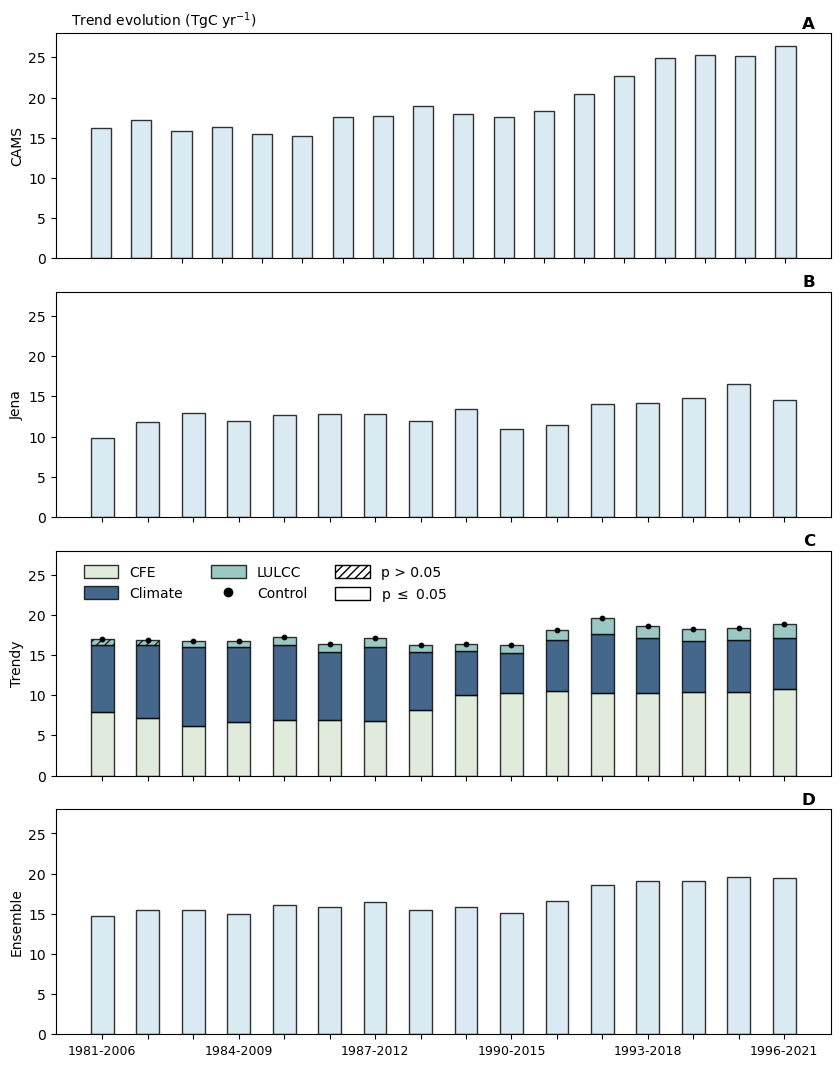

In [ ]:
# Trend evolution
n_models = 4
gs = gridspec.GridSpec(n_models, 1, width_ratios=[1], height_ratios=[1]*n_models, hspace=0.15)
fig = plt.figure(figsize=(10, 13))  
axs = np.empty((n_models), dtype=object)
for i in range(n_models):
    axs[i] = fig.add_subplot(gs[i])
colors = ['#dae6d3', '#16416e', '#83bbb4']

# 其余三个
models_to_plot = ['CAMS', 'Jena', 'Ensemble']
plot_idx = [0, 1, 3]
for i, model in enumerate(models_to_plot):
    ax = axs[plot_idx[i]]
    trend_roll = model_dict[model]['trend_roll']
    time_map = model_dict[model]['time_map']

    x_data = time_map[:, 1]
    y_data = trend_roll[:, 1]
    p_data = trend_roll[:, 0]

    y_data = y_data * 1000 # 转换为 TgC yr^-1
    bars = ax.bar(x_data, y_data,
                    color='#d1e5f0', width=0.5,
                    edgecolor='black', linewidth=1, alpha=0.8)

    for idx, rect in enumerate(bars):
        if p_data[idx] > 0.1:
            rect.set_hatch('////')

ax = axs[2]
trend_roll = model_dict['Trendy']['trend_roll'][:, 2:]
time_roll = model_dict['Trendy']['time_map'][2:]
x_data = time_roll[:, 1]
n_points = len(x_data)

# 分别记录正负值的堆叠底线
bottom_pos = np.zeros(n_points)
bottom_neg = np.zeros(n_points)

colors = ['#dae6d3', '#16416e', '#83bbb4']

for n_e, exp in enumerate(exp_list[1:]):
    y_data = trend_roll[n_e+1, :, 1]
    p_data = trend_roll[n_e+1, :, 0] 
    y_data = y_data * 1000 # 转换为 TgC yr^-1

    # 根据 y 值的正负选择对应的底线
    bottom = np.where(y_data > 0, bottom_pos, bottom_neg)
    
    bars = ax.bar(x_data, y_data, bottom=bottom, label=exp, 
                  color=colors[n_e % len(colors)], width=0.5,
                  edgecolor='black', linewidth=1, alpha=0.8)

    for idx, rect in enumerate(bars):
        if p_data[idx] > 0.1:
            rect.set_hatch('////')

    # 更新底线
    bottom_pos += np.maximum(y_data, 0)
    bottom_neg += np.minimum(y_data, 0)
ax.scatter(x_data, trend_roll[0, :, 1]*1000, color='black', s=10, zorder=5)  # 添加散点以突出显示 x 轴

custom_lines = [
    mpatches.Patch(facecolor=colors[i], edgecolor='black', linewidth=1, alpha=0.8) 
    for i in range(len(exp_list)-1)
]
custom_lines.append(Line2D([0], [0], marker='o', color='black', markerfacecolor='black', markersize=6, lw=0, label='Control'))
custom_lines.append(mpatches.Patch(facecolor='white', edgecolor='black', hatch='////', linewidth=1))
custom_lines.append(mpatches.Patch(facecolor='white', edgecolor='black', linewidth=1))
labels_legend = ['CFE', 'Climate', 'LULCC', 'Control', 'p > 0.05', 'p $\leq$ 0.05']
ax.legend(custom_lines, labels_legend, bbox_to_anchor=(0.02, 0.99), 
          loc='upper left', frameon=False, fontsize=10,
          handlelength=2.5, handleheight=1., ncols=3)

xticks_label = []
for i in range(n_points):
    start_year = int(time_roll[i, 0])
    end_year = int(time_roll[i, 1])
    xticks_label.append(f'{start_year}-{end_year}')

letters = ['A', 'B', 'C', 'D']
for i in range(4):
    ax = axs[i]
    ax.set_xticks(x_data)
    ax.set_ylim(0, 28)
    # ax.axhline(0, color='black', linewidth=1)
    if i != 3:
        ax.set_xticklabels([])
    else:
        display_labels = [label if i % 3 == 0 else "" for i, label in enumerate(xticks_label)]
        ax.set_xticklabels(display_labels, rotation=0, fontsize=9)
    ax.text(0.98, 1.01, letters[i], transform=ax.transAxes, ha='right', va='bottom', 
            fontsize=12, fontweight='bold')
    ax.text(-0.05, 0.5, model_list[i], transform=ax.transAxes, ha='center', va='center', 
            rotation=90, fontsize=10)

axs[0].text(0.02, 1.01, 'Trend evolution (TgC yr$^{-1}$)', fontsize=10,
        va='bottom', ha='left', transform=axs[0].transAxes)

fig.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/SI-fig/Part-2-CCA-trend-evo.png', dpi=500,
            bbox_inches='tight', pad_inches=0.1)